# Data Science III | Checkpoint 1

Clasificación de noticias AG News con PyTorch. Dataset: 8.000 noticias para entrenamiento/validación y 2.000 para prueba.


## 1. Entorno

Configuración reproducible y selección del dispositivo disponible.


In [1]:
from pathlib import Path
import os
ROOT = Path.cwd()
if not (ROOT / "src" / "train.py").exists() and (ROOT.parent / "src" / "train.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "src" / "train.py").exists(), "Ejecutar desde la raíz o notebooks/ del proyecto"
os.chdir(ROOT)
from src.train import Config, run_training, load_official_data, select_device
import torch
print("Raíz:", ROOT)
print("Versión PyTorch:", torch.__version__)
print("Dispositivo:", select_device())
print("Semilla del experimento: 42")

Raíz: /mnt/data/AGNews_Checkpoint1_Repositorio
Versión PyTorch: 2.10.0+cpu
Dispositivo: cpu
Semilla del experimento: 42


## 2. Dataset

Inspección de estructura y distribución de clases.


In [2]:
train_catedra, test_catedra = load_official_data(Config())
print("Train oficial:", train_catedra.shape, "| Test reservado:", test_catedra.shape)
print("Clases train:\n", train_catedra["label"].value_counts().sort_index())
print("Nulos train:", train_catedra.isna().sum().sum())

Train oficial: (8000, 2) | Test reservado: (2000, 2)
Clases train:
 label
Business    2000
Sci_Tech    2000
Sports      2000
World       2000
Name: count, dtype: int64
Nulos train: 0


## 3. Entrenamiento y validación

MLP con PyTorch, optimizador Adam y selección por pérdida de validación. El entrenamiento utiliza `src/train.py`.


In [3]:
config = Config(
    seed=42,
    max_features=6000,
    learning_rate=0.001,
    epochs=20,
    patience=5,
    batch_size=128,
    hidden_size=128,
    dropout=0.35,
)
resultados = run_training(config)
print("Mejor época:", resultados["best_epoch_by_val_loss"])
print(f"Test Accuracy: {resultados['test_accuracy']:.4f}")
print(f"Test F1-macro: {resultados['test_f1_macro']:.4f}")

PyTorch 2.10.0+cpu | device=cpu | parámetros=768,644
AG News cátedra: train=6400, val=1600, test reservado=2000
TF-IDF: 6000 atributos (fit exclusivamente en train)


Epoch 01 | train loss 1.0743 | val loss 1.1016 | val acc 0.8506 | val F1macro 0.8481


Epoch 02 | train loss 0.5570 | val loss 0.6324 | val acc 0.8744 | val F1macro 0.8732


Epoch 03 | train loss 0.3398 | val loss 0.4484 | val acc 0.8825 | val F1macro 0.8819


Epoch 04 | train loss 0.2499 | val loss 0.3902 | val acc 0.8800 | val F1macro 0.8792


...

Epoch 11 | train loss 0.0681 | val loss 0.3517 | val acc 0.8812 | val F1macro 0.8807


Epoch 12 | train loss 0.0590 | val loss 0.3524 | val acc 0.8812 | val F1macro 0.8807


Epoch 13 | train loss 0.0519 | val loss 0.3566 | val acc 0.8819 | val F1macro 0.8813


Early stopping: sin mejora 5 épocas.


MEJOR ÉPOCA: 8 | TEST accuracy=0.8820 | F1macro=0.8821
Mejor época: 8
Test Accuracy: 0.8820
Test F1-macro: 0.8821


## 4. Métricas por época

Evolución de Loss, Accuracy y F1-macro.


,epoch,train_loss,train_accuracy,train_f1_macro,val_loss,val_accuracy,val_f1_macro,val_f1_weighted
0,1,1.0743,0.8920,0.8909,1.1016,0.8506,0.8481,0.8481
1,2,0.5570,0.9122,0.9117,0.6324,0.8744,0.8732,0.8732
2,3,0.3398,0.9297,0.9295,0.4484,0.8825,0.8819,0.8819
3,4,0.2499,0.9453,0.9452,0.3902,0.8800,0.8792,0.8792
4,5,0.1966,0.9597,0.9597,0.3634,0.8856,0.8850,0.8850
5,6,0.1588,0.9702,0.9701,0.3504,0.8862,0.8857,0.8857
6,7,0.1304,0.9775,0.9775,0.3448,0.8850,0.8845,0.8845
7,8,0.1083,0.9828,0.9828,0.3441,0.8850,0.8845,0.8845
8,9,0.0918,0.9881,0.9881,0.3472,0.8831,0.8824,0.8824
9,10,0.0784,0.9922,0.9922,0.3462,0.8844,0.8839,0.8839


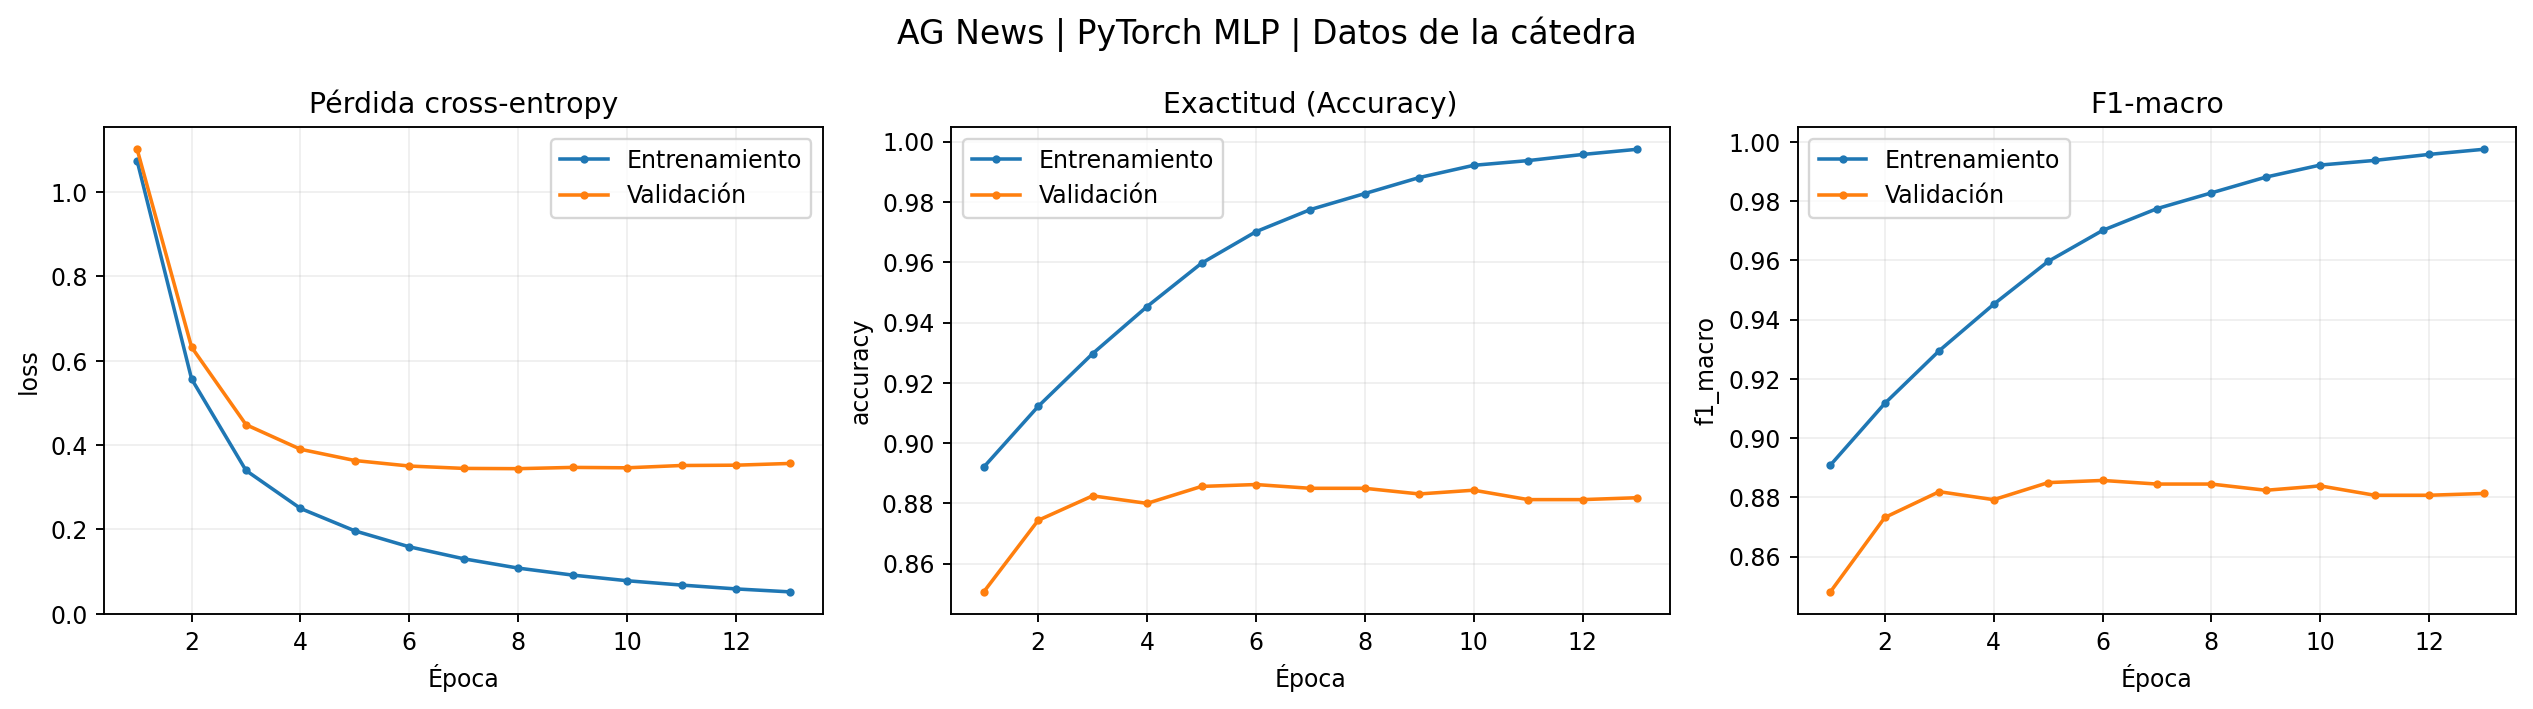

In [4]:
import pandas as pd
from IPython.display import display, Image
historial = pd.read_csv(ROOT / "outputs" / "historial_epocas.csv")
display(historial.round(4))
display(Image(filename=str(ROOT / "outputs" / "curvas_entrenamiento_validacion.png"), width=950))

## 5. Evaluación final

Reporte por clase y matriz de confusión sobre el test reservado.


,Unnamed: 0,precision,recall,f1-score,support
0,Business,0.8304,0.842,0.8361,500.000
1,Sci_Tech,0.8495,0.858,0.8537,500.000
2,Sports,0.9481,0.950,0.9491,500.000
3,World,0.9014,0.878,0.8896,500.000
4,accuracy,0.8820,0.882,0.8820,0.882
5,macro avg,0.8824,0.882,0.8821,2000.000
6,weighted avg,0.8824,0.882,0.8821,2000.000


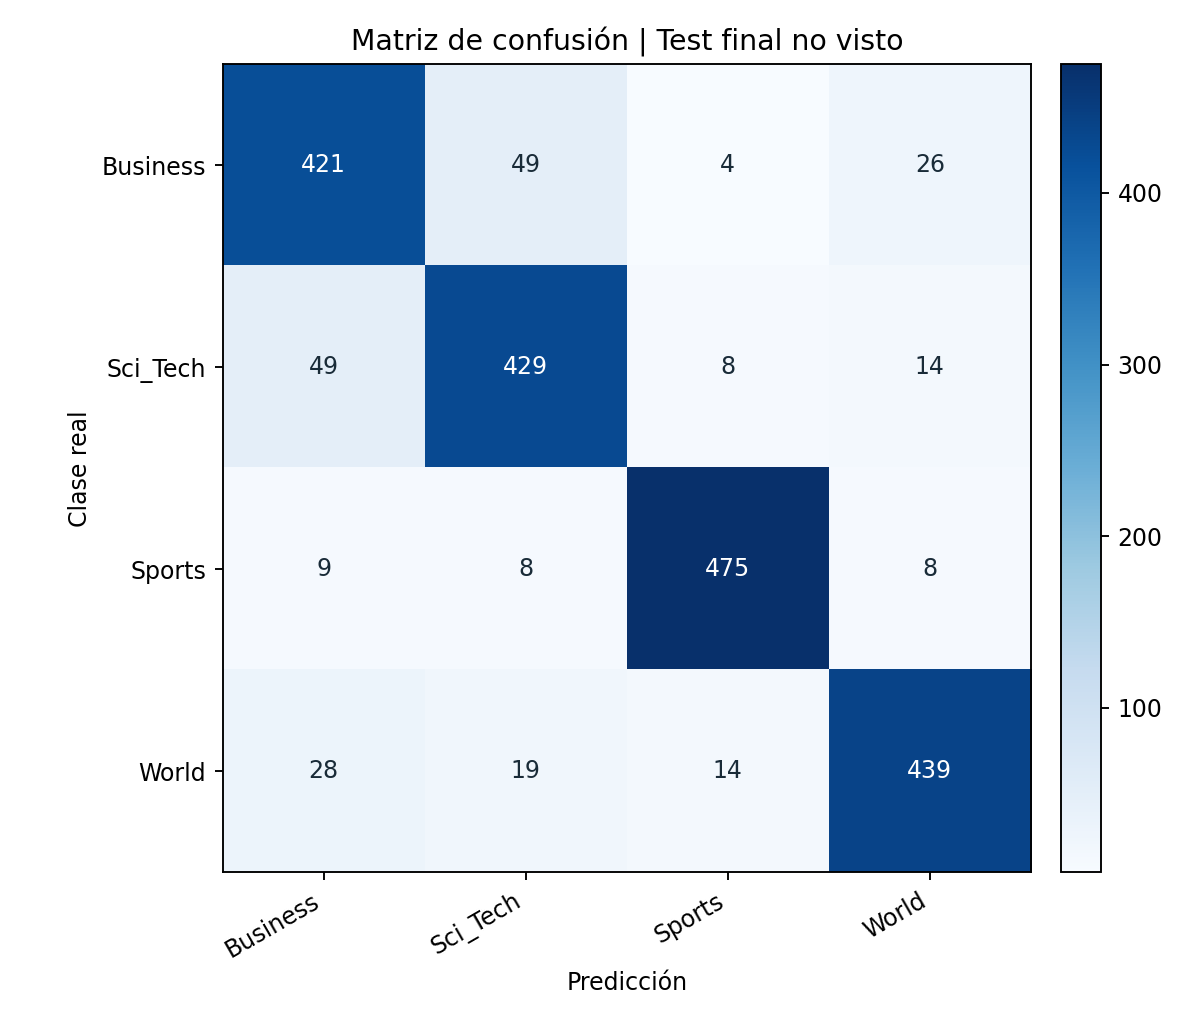

In [5]:
display(pd.read_csv(ROOT / "outputs" / "reporte_clasificacion_test.csv").round(4))
display(Image(filename=str(ROOT / "outputs" / "matriz_confusion_test.png"), width=620))

## 6. Conclusión

La mejor pérdida de validación se obtuvo en la época 8 (0.3441). El aumento posterior, frente al descenso continuo de la pérdida de entrenamiento, indica posible sobreajuste. Con los mejores pesos se obtuvo 88.20 % de Accuracy y 88.21 % de F1-macro en test.
